# Quantile mapping re-scored on the official metric (not built)

**The question:** the quantile-mapping post-step (`docs/quantile_mapping.md`) lost on the old
per-run TIMSE because it removes the upward offset that metric favours. Does it help on the
official metric, which counts RMSE and a per-lead percentile TIMSE?

**The run** (`python -m training.quantile_mapping`, `--metric official`): the submitted linear
model (official loss weights, blend 0.25) is refitted on each of the six yearly folds; each lead's
forecast is mapped through F_y^-1(F_f(f)) learned on the training runs, blended at strength alpha,
and scored with the official S_final against the official truth.

**Decision rule** (set before running): more than 1% better than alpha = 0, winning at least 4 of
6 folds.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import quantile_mapping as qm

df = pd.read_csv(qm.EXPERIMENTS / "quantile_mapping_official.csv").set_index("fold")
alphas = qm.ALPHAS
ref = df["linear a=0 | s_final"]
rows = {}
for a in alphas:
    s = df[f"linear a={a:g} | s_final"]
    rows[a] = {"S_final": s.mean(), "vs a=0 %": 100 * (np.exp(np.log(s / ref).mean()) - 1),
               "folds won": int((s < ref).sum()),
               **{k: df[f"linear a={a:g} | {k}"].mean()
                  for k in ("rmse", "trmse", "bias", "bias 72h", "spread")}}
summary = pd.DataFrame(rows).T
summary.index.name = "alpha"
with pd.option_context("display.float_format", "{:.3f}".format):
    display(summary)

,S_final,vs a=0 %,folds won,rmse,trmse,bias,bias 72h,spread
alpha,,,,,,,,
0.000,88.486,0.000,0.000,68.282,116.198,21.728,29.703,0.796
0.250,88.524,0.017,2.000,68.075,116.691,18.561,25.019,0.833
0.500,88.893,0.453,2.000,68.275,117.357,15.395,20.334,0.871
0.750,89.593,1.311,0.000,68.882,118.193,12.228,15.650,0.909
1.000,90.615,2.578,0.000,69.884,119.191,9.062,10.965,0.948


## 1. By fold (% change in S_final against the shipped model)

,a=0.25,a=0.5,a=0.75,a=1
fold,,,,
2019-10,-0.63,-0.24,1.21,3.71
2020-10,0.23,0.91,2.03,3.57
2021-10,0.41,1.10,2.04,3.24
2022-10,0.06,0.41,1.05,1.96
2023-10,0.16,0.62,1.39,2.47
2024-10,-0.12,-0.07,0.15,0.55


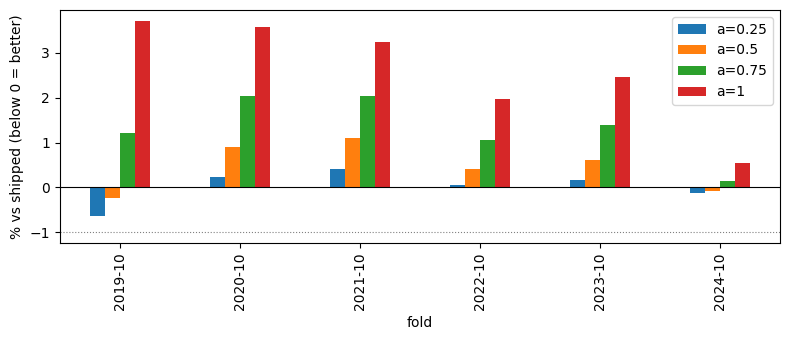

In [2]:
change = pd.DataFrame({f"a={a:g}": 100 * (df[f"linear a={a:g} | s_final"] / ref - 1)
                       for a in alphas[1:]})
display(change.round(2))
ax = change.plot.bar(figsize=(8, 3.5))
ax.axhline(0, color="k", lw=.8)
ax.axhline(-1, color="grey", ls=":", lw=.8)
ax.set_ylabel("% vs shipped (below 0 = better)")
plt.tight_layout()

## 2. What the map changes: the score's two terms, bias and spread

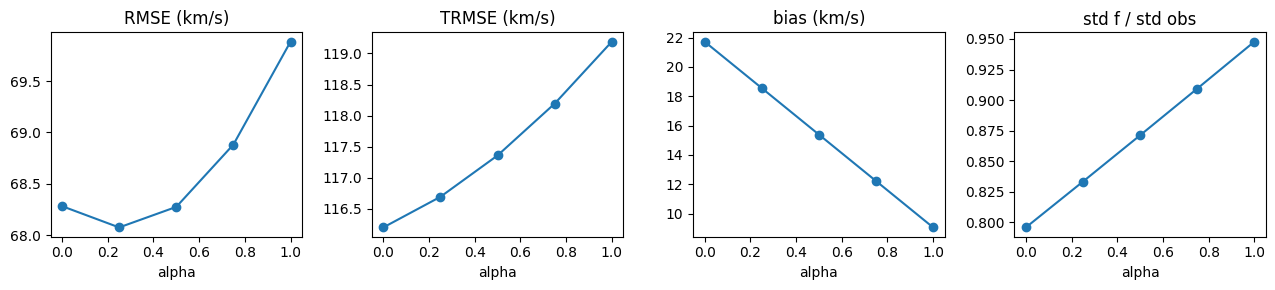

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, k, label in zip(axes, ("rmse", "trmse", "bias", "spread"),
                        ("RMSE (km/s)", "TRMSE (km/s)", "bias (km/s)", "std f / std obs"),
                        strict=True):
    ax.plot(summary.index, summary[k], "o-")
    ax.set_xlabel("alpha")
    ax.set_title(label)
plt.tight_layout()

## 3. Per-fold bias against strength

In [4]:
bias = pd.DataFrame({f"a={a:g}": df[f"linear a={a:g} | bias"] for a in alphas})
display(bias.round(1))

,a=0,a=0.25,a=0.5,a=0.75,a=1
fold,,,,,
2019-10,14.1,8.7,3.4,-2.0,-7.4
2020-10,20.5,17.1,13.6,10.2,6.7
2021-10,8.5,6.4,4.3,2.1,0.0
2022-10,17.0,14.7,12.4,10.1,7.8
2023-10,27.7,23.7,19.7,15.7,11.7
2024-10,42.5,40.8,39.0,37.3,35.5


## Findings

1. **Not built.** Mild mapping ties with the shipped model (alpha 0.25: +0.02%, 2 of 6 folds);
   stronger mapping is worse (+0.45% at 0.5, +2.58% at 1, no fold won).
2. **The map works as designed but the metric doesn't reward it.** It widens the forecasts
   (spread 0.80 to 0.95 of the observed) and cuts the mean bias from +21.7 to +9.1 km/s, yet the
   tail term TRMSE rises at every strength (116.2 to 119.2 km/s): a wider forecast that
   mistimes a stream is penalised at the extremes the percentile weights emphasise.
3. **RMSE improves only slightly, at alpha 0.25** (68.28 to 68.08 km/s), which the tail term
   offsets.
4. **The remaining bias is fold-specific,** largest in the fast 2024-10 fold, and a map learned on
   the training years' distribution can't remove it.

**Decision:** the post-step stays unbuilt; the submitted linear model is unchanged.